In [ ]:
import pandas as pd

# Load datasets
low = pd.read_csv("neonatal_low_burden.csv")
moderate = pd.read_csv("neonatal_moderate_burden.csv")
high = pd.read_csv("neonatal_high_burden.csv")
sensor = pd.read_csv("realistic_nicu_sensor_data.csv")

# Add risk label
low["risk"] = 0
moderate["risk"] = 1
high["risk"] = 2

# Combine clinical data
clinical = pd.concat([low, moderate, high], ignore_index=True)

# Convert infant_id → numeric id
sensor["id"] = sensor["infant_id"].str.extract("(\d+)").astype(int)

# Merge
data = pd.merge(sensor, clinical, on="id", how="left")

print(data.shape)
data.head()

<>:18: SyntaxWarning: invalid escape sequence '\d'
<>:18: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_906/2511213946.py:18: SyntaxWarning: invalid escape sequence '\d'
  sensor["id"] = sensor["infant_id"].str.extract("(\d+)").astype(int)


(30000, 40)


,timestamp,infant_id,gest_age_weeks,device_id,infant_baseline_id,radiation_counts_cpm,dose_rate_μSv_h,cumulative_dose_μSv,magnetic_field_μT,field_direction_deg,...,apgar_1min,apgar_5min,temperature_c,heart_rate_bpm_y,respiratory_rate_bpm,spo2_percent,bw_category,preterm_category,primary_outcome,risk
0,2025-12-29T10:00:00,infant_008,28,DEV_005,infant_008_base_52,70,0.7790,0.0002,16.53,7.4,...,6,8,37.3,143,44,98,LBW,Late_preterm,healthy,0
1,2025-12-29T10:00:00,infant_008,28,DEV_005,infant_008_base_52,70,0.7790,0.0002,16.53,7.4,...,7,6,36.6,147,47,97,Normal_BW,Term,healthy,1
2,2025-12-29T10:00:00,infant_008,28,DEV_005,infant_008_base_52,70,0.7790,0.0002,16.53,7.4,...,5,5,36.8,137,40,98,LBW,Late_preterm,healthy,2
3,2025-12-29T10:00:01,infant_003,36,DEV_004,infant_003_base_52,91,0.8953,0.0005,14.94,339.2,...,9,10,37.2,149,55,98,Normal_BW,Term,healthy,0
4,2025-12-29T10:00:01,infant_003,36,DEV_004,infant_003_base_52,91,0.8953,0.0005,14.94,339.2,...,10,8,36.8,120,51,94,Normal_BW,Term,healthy,1


CLEAN DATA

In [ ]:
print(list(data.columns))

['timestamp', 'infant_id', 'gest_age_weeks', 'device_id', 'infant_baseline_id', 'radiation_counts_cpm', 'dose_rate_μSv_h', 'cumulative_dose_μSv', 'magnetic_field_μT', 'field_direction_deg', 'emf_peak_μT', 'electric_field_V_m', 'frequency_Hz', 'field_gradient_V_m2', 'temperature_C', 'relative_humidity_pct', 'dew_point_C', 'heart_rate_bpm_x', 'spo2_pct', 'perfusion_index_pct', 'is_anomaly', 'anomaly_severity', 'id', 'sex', 'gestational_age_weeks', 'birth_weight_g', 'head_circumference_cm', 'maternal_age_years', 'parity', 'delivery_mode', 'apgar_1min', 'apgar_5min', 'temperature_c', 'heart_rate_bpm_y', 'respiratory_rate_bpm', 'spo2_percent', 'bw_category', 'preterm_category', 'primary_outcome', 'risk']


In [ ]:
# make everything uniform
data.columns = data.columns.str.strip().str.lower().str.replace(" ", "_")

print("Columns after cleaning:", data.columns)

Columns after cleaning: Index(['timestamp', 'infant_id', 'gest_age_weeks', 'device_id',
       'infant_baseline_id', 'radiation_counts_cpm', 'dose_rate_μsv_h',
       'cumulative_dose_μsv', 'magnetic_field_μt', 'field_direction_deg',
       'emf_peak_μt', 'electric_field_v_m', 'frequency_hz',
       'field_gradient_v_m2', 'temperature_c', 'relative_humidity_pct',
       'dew_point_c', 'heart_rate_bpm_x', 'spo2_pct', 'perfusion_index_pct',
       'is_anomaly', 'anomaly_severity', 'id', 'sex', 'gestational_age_weeks',
       'birth_weight_g', 'head_circumference_cm', 'maternal_age_years',
       'parity', 'delivery_mode', 'apgar_1min', 'apgar_5min', 'temperature_c',
       'heart_rate_bpm_y', 'respiratory_rate_bpm', 'spo2_percent',
       'bw_category', 'preterm_category', 'primary_outcome', 'risk'],
      dtype='object')


In [ ]:
for col in data.columns:
    print(col)

timestamp
infant_id
gest_age_weeks
device_id
infant_baseline_id
radiation_counts_cpm
dose_rate_μsv_h
cumulative_dose_μsv
magnetic_field_μt
field_direction_deg
emf_peak_μt
electric_field_v_m
frequency_hz
field_gradient_v_m2
temperature_c
relative_humidity_pct
dew_point_c
heart_rate_bpm_x
spo2_pct
perfusion_index_pct
is_anomaly
anomaly_severity
id
sex
gestational_age_weeks
birth_weight_g
head_circumference_cm
maternal_age_years
parity
delivery_mode
apgar_1min
apgar_5min
temperature_c
heart_rate_bpm_y
respiratory_rate_bpm
spo2_percent
bw_category
preterm_category
primary_outcome
risk


In [ ]:
# =========================
# STEP A: CLEAN COLUMN NAMES
# =========================
data.columns = (
    data.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^\w]", "_", regex=True)
    .str.replace("_+", "_", regex=True)
)

# =========================
# STEP B: SELECT CORRECT COLUMNS
# =========================

data = data.rename(columns={
    "heart_rate_bpm_x": "heart_rate",
    "spo2_pct": "spo2",
    "radiation_counts_cpm": "radiation_level",
    "emf_peak_μt": "emf_level",
    "relative_humidity_pct": "humidity",
    "birth_weight_g": "birth_weight_grams",
    "apgar_1min": "apgar_score_1min"
})

# =========================
# STEP C: DROP DUPLICATES
# =========================

data = data.drop(columns=[
    "heart_rate_bpm_y",
    "spo2_percent"
], errors="ignore")

# =========================
# STEP D: FINAL COLUMN SELECTION
# =========================

required_cols = [
    "timestamp",
    "id",
    "heart_rate",
    "spo2",
    "radiation_level",
    "emf_level",
    "humidity",
    "gestational_age_weeks",
    "birth_weight_grams",
    "apgar_score_1min",
    "risk"
]

data = data[required_cols]

# =========================
# STEP E: VERIFY
# =========================

print("Final columns:", data.columns)
print(data.head())

Final columns: Index(['timestamp', 'id', 'heart_rate', 'spo2', 'radiation_level', 'emf_level',
       'humidity', 'gestational_age_weeks', 'birth_weight_grams',
       'apgar_score_1min', 'risk'],
      dtype='object')
             timestamp  id  heart_rate  spo2  radiation_level  emf_level  \
0  2025-12-29T10:00:00   8  129.871689  95.6               70      16.53   
1  2025-12-29T10:00:00   8  129.871689  95.6               70      16.53   
2  2025-12-29T10:00:00   8  129.871689  95.6               70      16.53   
3  2025-12-29T10:00:01   3  136.318291  95.8               91      14.94   
4  2025-12-29T10:00:01   3  136.318291  95.8               91      14.94   

   humidity  gestational_age_weeks  birth_weight_grams  apgar_score_1min  risk  
0      48.9                   35.0                2230                 6     0  
1      48.9                   39.2                2970                 7     1  
2      48.9                   35.4                2300                 5     2  


In [ ]:
print(type(data))
print(data.shape)

<class 'pandas.core.frame.DataFrame'>
(30000, 11)


In [ ]:
print(data.columns.tolist())

['timestamp', 'id', 'heart_rate', 'spo2', 'radiation_level', 'emf_level', 'humidity', 'gestational_age_weeks', 'birth_weight_grams', 'apgar_score_1min', 'risk']


In [ ]:
print(data.dtypes)

timestamp                 object
id                         int64
heart_rate               float64
spo2                     float64
radiation_level            int64
emf_level                float64
humidity                 float64
gestational_age_weeks    float64
birth_weight_grams         int64
apgar_score_1min           int64
risk                       int64
dtype: object


In [ ]:
print(data[cols_to_scale].head())

   heart_rate  spo2  radiation_level  emf_level  humidity
0  129.871689  95.6               70      16.53      48.9
1  129.871689  95.6               70      16.53      48.9
2  129.871689  95.6               70      16.53      48.9
3  136.318291  95.8               91      14.94      53.2
4  136.318291  95.8               91      14.94      53.2


In [ ]:
scaled = scaler.fit_transform(data[cols_to_scale])

print(type(scaled))
print(scaled.shape)

<class 'numpy.ndarray'>
(30000, 5)


In [ ]:
data[cols_to_scale] = scaler.fit_transform(data[cols_to_scale])

In [ ]:
scaled = scaler.fit_transform(data[cols_to_scale])

scaled_df = pd.DataFrame(
    scaled,
    columns=cols_to_scale,
    index=data.index
)

data.update(scaled_df)

print(data.head())

             timestamp  id  heart_rate      spo2  radiation_level  emf_level  \
0  2025-12-29T10:00:00   8    0.349402  0.549020         0.223301   0.440324   
1  2025-12-29T10:00:00   8    0.349402  0.549020         0.223301   0.440324   
2  2025-12-29T10:00:00   8    0.349402  0.549020         0.223301   0.440324   
3  2025-12-29T10:00:01   3    0.426232  0.562092         0.427184   0.348204   
4  2025-12-29T10:00:01   3    0.426232  0.562092         0.427184   0.348204   

   humidity  gestational_age_weeks  birth_weight_grams  apgar_score_1min  risk  
0  0.435897                   35.0                2230                 6     0  
1  0.435897                   39.2                2970                 7     1  
2  0.435897                   35.4                2300                 5     2  
3  0.711538                   39.6                3010                 9     0  
4  0.711538                   37.1                2600                10     1  


NORMALIZATION

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

cols_to_scale = [
    "heart_rate",
    "spo2",
    "radiation_level",
    "emf_level",
    "humidity"
]

data[cols_to_scale] = scaler.fit_transform(data[cols_to_scale])

In [ ]:
data["BSI"] = (
    abs(data["heart_rate"] - 0.5) +   # deviation from normal HR
    (1 - data["spo2"]) +              # lower oxygen = stress
    data["radiation_level"] +         # radiation stress
    data["emf_level"] +               # EMF stress
    abs(data["humidity"] - 0.5)       # environmental discomfort
)

In [ ]:
print(data[["heart_rate","spo2","radiation_level","BSI"]].head())

   heart_rate      spo2  radiation_level       BSI
0    0.349402  0.549020         0.223301  1.329306
1    0.349402  0.549020         0.223301  1.329306
2    0.349402  0.549020         0.223301  1.329306
3    0.426232  0.562092         0.427184  1.498604
4    0.426232  0.562092         0.427184  1.498604


In [ ]:
print(data.isnull().sum())

timestamp                0
id                       0
heart_rate               0
spo2                     0
radiation_level          0
emf_level                0
humidity                 0
gestational_age_weeks    0
birth_weight_grams       0
apgar_score_1min         0
risk                     0
BSI                      0
dtype: int64


STEP 6A: SORT DATA

In [ ]:
data = data.sort_values(by=["id", "timestamp"])

STEP 6B: SELECT FEATURES FOR LSTM

In [ ]:
features = [
    "heart_rate",
    "spo2",
    "radiation_level",
    "emf_level",
    "humidity",
    "BSI"
]

STEP 6C: CREATE SEQUENCES

In [ ]:
import numpy as np

sequence_length = 10

def create_sequences(df, seq_len):
    sequences = []

    for infant_id in df["id"].unique():
        infant_data = df[df["id"] == infant_id]

        values = infant_data[features].values

        for i in range(len(values) - seq_len):
            seq = values[i:i+seq_len]
            sequences.append(seq)

    return np.array(sequences)

X_seq = create_sequences(data, sequence_length)

print("Sequence shape:", X_seq.shape)

Sequence shape: (29900, 10, 6)


Extract LOW RISK DATA

In [ ]:
normal_data = data[data["risk"] == 0]
X_normal = create_sequences(normal_data, sequence_length)

print("Normal sequences:", X_normal.shape)

Normal sequences: (9900, 10, 6)


BUILD LSTM AUTOENCODER

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, RepeatVector

timesteps = X_normal.shape[1]
n_features = X_normal.shape[2]

inputs = Input(shape=(timesteps, n_features))

encoded = LSTM(64, activation='relu', return_sequences=False)(inputs)
decoded = RepeatVector(timesteps)(encoded)
decoded = LSTM(n_features, activation='relu', return_sequences=True)(decoded)

autoencoder = Model(inputs, decoded)

autoencoder.compile(optimizer='adam', loss='mse')

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 10, 6)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 10, 6)          │         1,704 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,880 (77.66 KB)

 Trainable params: 19,880 (77.66 KB)

 Non-trainable params: 0 (0.00 B)

TRAIN

In [ ]:
history = autoencoder.fit(
    X_normal, X_normal,
    epochs=15,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.0675 - val_loss: 0.0206
Epoch 2/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.0199 - val_loss: 0.0198
Epoch 3/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0194 - val_loss: 0.0193
Epoch 4/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0190 - val_loss: 0.0190
Epoch 5/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0187 - val_loss: 0.0186
Epoch 6/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0184 - val_loss: 0.0185
Epoch 7/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0182 - val_loss: 0.0183
Epoch 8/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0182 - val_loss: 0.0182
Epoch 9/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0181 - val_loss: 0.0182
Epoch 10/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0180 - val_loss: 0.0181
Epoch 11/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0179 - val_loss: 0.0180
Epoch 12/15
279/279 ━━━━━━━━━━━━━━━━━━━━ 6s 

ANOMALY DETECTION

In [ ]:
# Reconstruction
reconstructions = autoencoder.predict(X_seq)

# Error
loss = np.mean(np.abs(reconstructions - X_seq), axis=(1,2))

# Threshold
threshold = np.percentile(loss, 95)

# Anomaly detection
anomalies = loss > threshold

935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step


VISUALIZATION

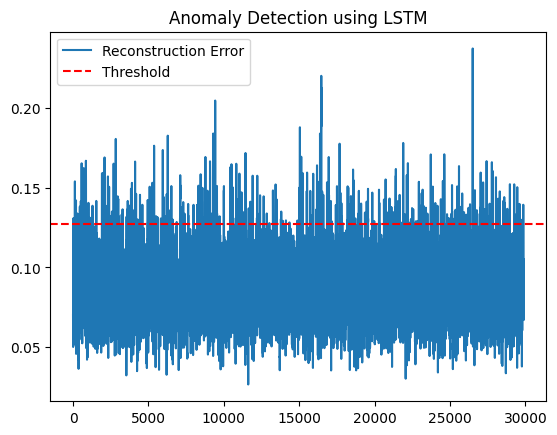

In [ ]:
import matplotlib.pyplot as plt

plt.plot(loss, label="Reconstruction Error")
plt.axhline(threshold, color='r', linestyle='--', label="Threshold")
plt.legend()
plt.title("Anomaly Detection using LSTM")
plt.show()

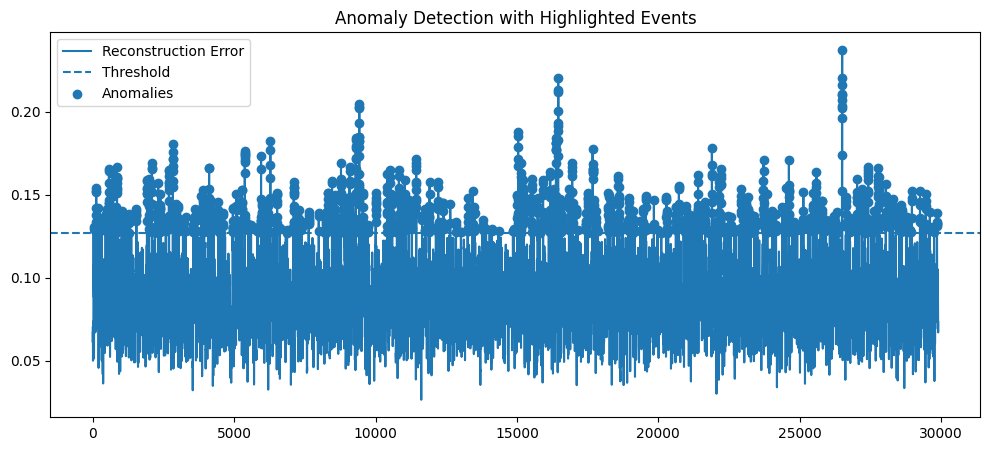

In [ ]:
import numpy as np

anomaly_points = np.where(loss > threshold)[0]

plt.figure(figsize=(12,5))
plt.plot(loss, label="Reconstruction Error")
plt.axhline(threshold, linestyle='--', label="Threshold")

plt.scatter(anomaly_points, loss[anomaly_points], label="Anomalies")

plt.legend()
plt.title("Anomaly Detection with Highlighted Events")
plt.show()

XG Boost

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

X_static = data[
    [
        "gestational_age_weeks",
        "birth_weight_grams",
        "apgar_score_1min"
    ]
]

y_static = data["risk"]

X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split(
    X_static,
    y_static,
    test_size=0.2,
    random_state=42,
    stratify=y_static
)

model_xgb = XGBClassifier(
    random_state=42,
    eval_metric="mlogloss"
)

model_xgb.fit(X_train_xgb, y_train_xgb)

print(model_xgb.score(X_test_xgb, y_test_xgb))



0.9673312112581672


In [ ]:
X_compare = data[
    [
        "gestational_age_weeks",
        "birth_weight_grams",
        "apgar_score_1min"
    ]
]

y_compare = data["risk"]

from sklearn.model_selection import train_test_split

X_train_cmp, X_test_cmp, y_train_cmp, y_test_cmp = train_test_split(
    X_compare,
    y_compare,
    test_size=0.2,
    random_state=42,
    stratify=y_compare
)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="mlogloss"
    )
}

results = []

for name, model in models.items():

    model.fit(X_train_cmp, y_train_cmp)

    y_pred = model.predict(X_test_cmp)

    results.append([
        name,
        accuracy_score(y_test_cmp, y_pred),
        precision_score(y_test_cmp, y_pred, average="weighted"),
        recall_score(y_test_cmp, y_pred, average="weighted"),
        f1_score(y_test_cmp, y_pred, average="weighted")
    ])

comparison = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

comparison = comparison.round(4)

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.5250,0.5219,0.5250,0.5178
1,Decision Tree,0.9673,0.9702,0.9673,0.9673
2,Random Forest,0.9673,0.9702,0.9673,0.9673
3,XGBoost,0.9673,0.9702,0.9673,0.9673


In [ ]:
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Predict probabilities
y_score = model_xgb.predict_proba(X_test)

# Convert labels to one-hot
classes = [0, 1, 2]
y_test_bin = label_binarize(y_test, classes=classes)

# Plot
plt.figure(figsize=(7,6))

colors = ["blue", "orange", "green"]

for i, color in zip(range(3), colors):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        color=color,
        linewidth=2,
        label=f"Class {i} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0,1],
    [0,1],
    "k--",
    linewidth=1.5
)

plt.xlim([0,1])
plt.ylim([0,1.05])

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Multiclass ROC Curve (One-vs-Rest)")
plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.savefig(
    "multiclass_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

ValueError: feature_names mismatch: ['gestational_age_weeks', 'birth_weight_grams', 'apgar_score_1min'] ['infant_id', 'heart_rate', 'spo2', 'radiation_level', 'emf_level', 'humidity', 'gestational_age_weeks', 'birth_weight_grams', 'apgar_score_1min']
training data did not have the following fields: radiation_level, emf_level, infant_id, humidity, heart_rate, spo2

In [ ]:
# XGBoost probability
xgb_probs = model_xgb.predict_proba(X_static)[:,1]

# match sizes
xgb_probs = xgb_probs[:len(loss)]

# final score
final_score = 0.4 * xgb_probs + 0.6 * loss

# scale to 0–100
final_score = 100 * (final_score - final_score.min()) / (final_score.max() - final_score.min())

print(final_score[:10])

[ 4.95958814 80.80513287  4.58155866  3.94149628 80.16367707  4.26846529
  4.66326419 80.21891265  3.17938173  2.67499983]


In [ ]:
def risk_label(score):
    if score < 30:
        return "SAFE"
    elif score < 70:
        return "WARNING"
    else:
        return "CRITICAL"

risk_levels = [risk_label(s) for s in final_score]

print(risk_levels[:10])

['SAFE', 'CRITICAL', 'SAFE', 'SAFE', 'CRITICAL', 'SAFE', 'SAFE', 'CRITICAL', 'SAFE', 'SAFE']


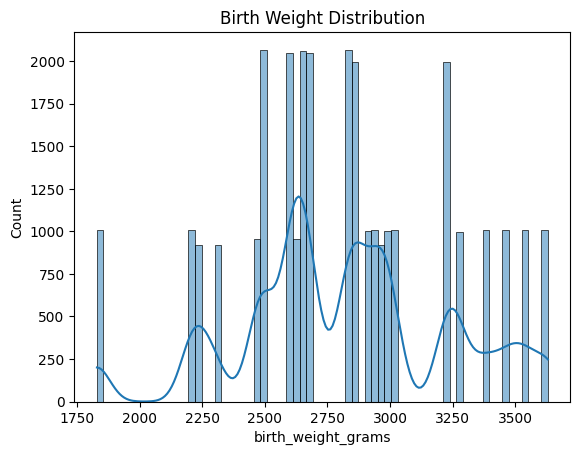

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data["birth_weight_grams"], kde=True)
plt.title("Birth Weight Distribution")
plt.show()

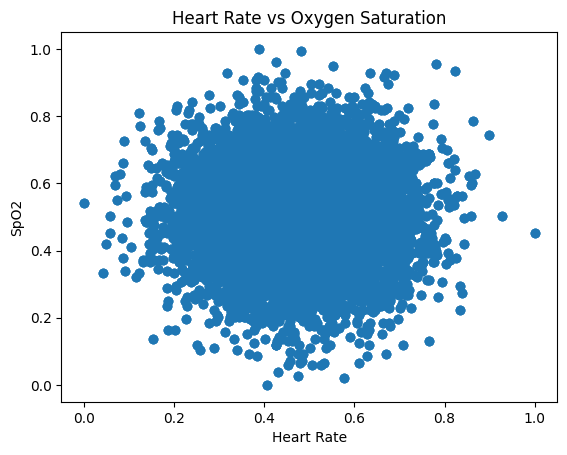

In [ ]:
plt.scatter(data["heart_rate"], data["spo2"])
plt.xlabel("Heart Rate")
plt.ylabel("SpO2")
plt.title("Heart Rate vs Oxygen Saturation")
plt.show()

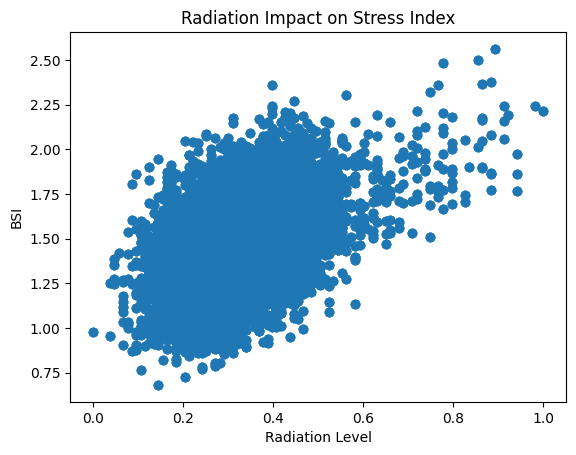

In [ ]:
plt.scatter(data["radiation_level"], data["BSI"])
plt.xlabel("Radiation Level")
plt.ylabel("BSI")
plt.title("Radiation Impact on Stress Index")
plt.show()

In [ ]:
numeric_data = data.select_dtypes(include=["number"])

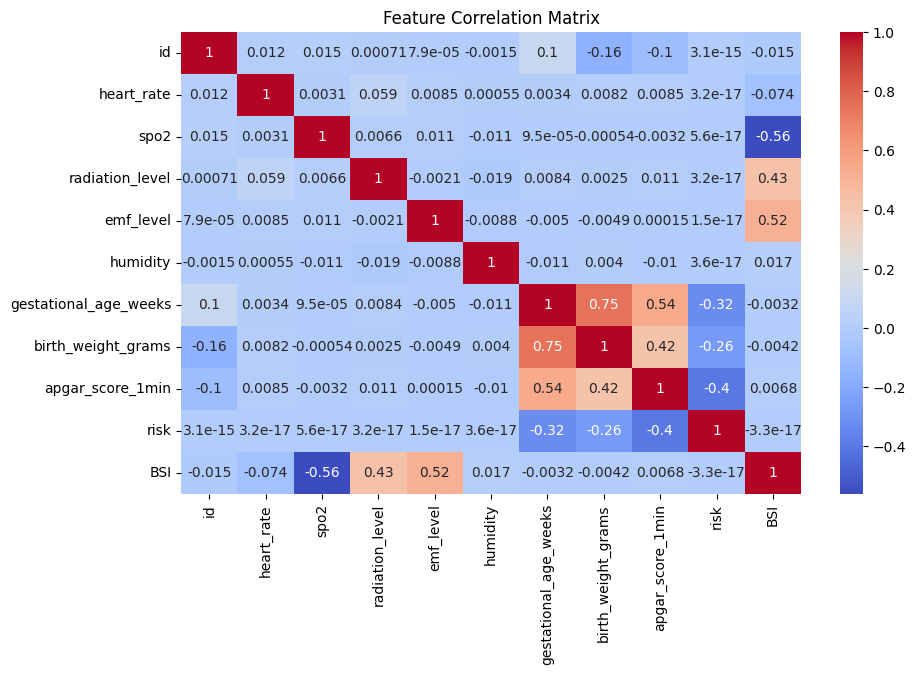

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Matrix")
plt.show()

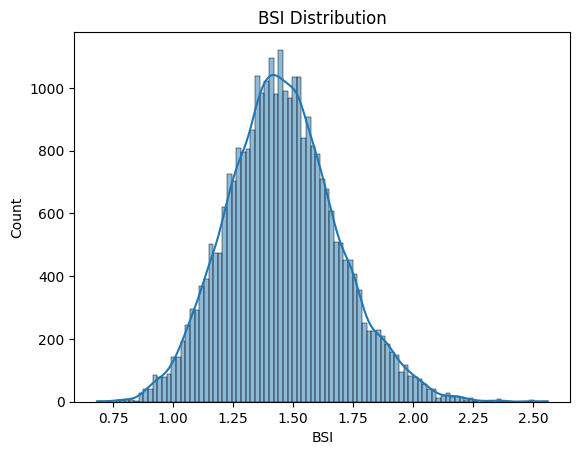

In [ ]:
sns.histplot(data["BSI"], kde=True)
plt.title("BSI Distribution")
plt.show()

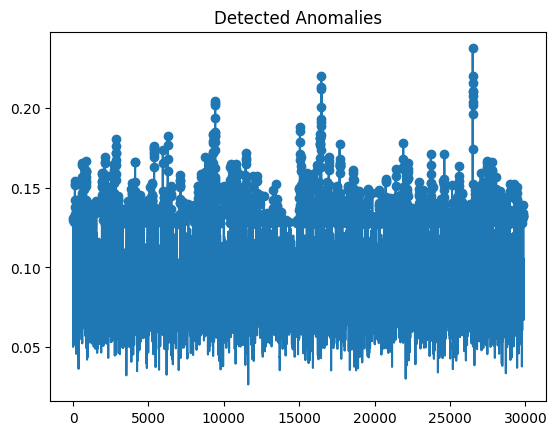

In [ ]:
import numpy as np

anomaly_points = np.where(loss > threshold)[0]

plt.plot(loss)
plt.scatter(anomaly_points, loss[anomaly_points])
plt.title("Detected Anomalies")
plt.show()

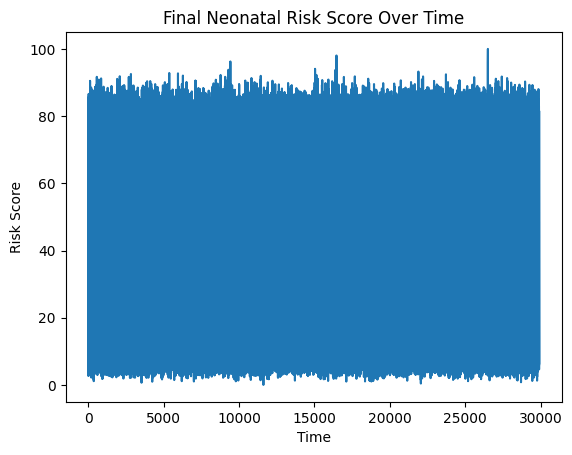

In [ ]:
plt.plot(final_score)
plt.title("Final Neonatal Risk Score Over Time")
plt.xlabel("Time")
plt.ylabel("Risk Score")
plt.show()

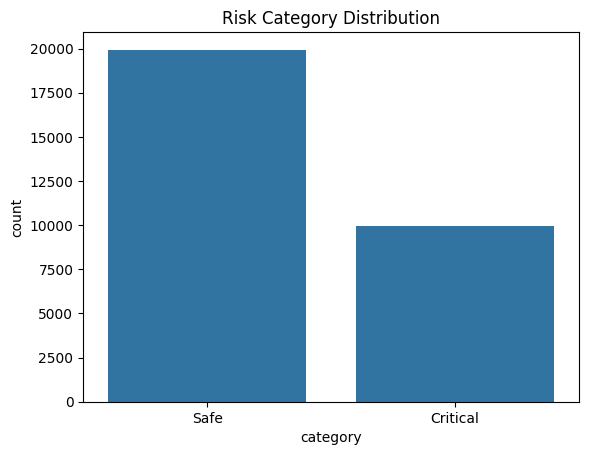

In [ ]:
import pandas as pd

risk_df = pd.DataFrame({"score": final_score})
risk_df["category"] = risk_df["score"].apply(
    lambda x: "Safe" if x<30 else "Warning" if x<70 else "Critical"
)

sns.countplot(x="category", data=risk_df)
plt.title("Risk Category Distribution")
plt.show()

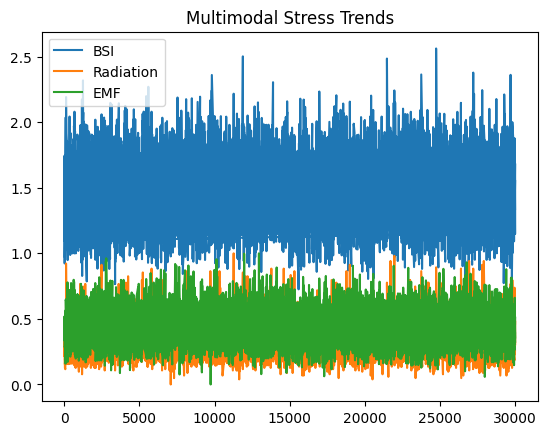

In [ ]:
plt.plot(data["BSI"], label="BSI")
plt.plot(data["radiation_level"], label="Radiation")
plt.plot(data["emf_level"], label="EMF")
plt.legend()
plt.title("Multimodal Stress Trends")
plt.show()

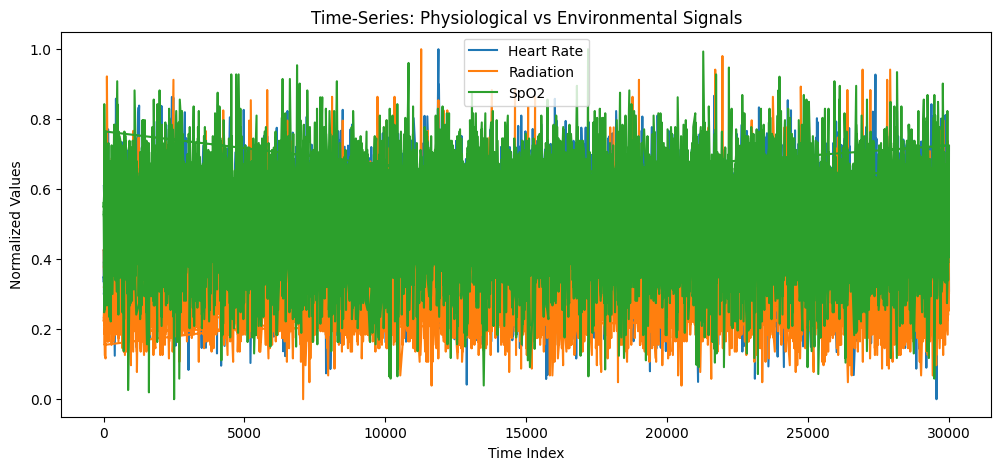

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(data["heart_rate"], label="Heart Rate")
plt.plot(data["radiation_level"], label="Radiation")
plt.plot(data["spo2"], label="SpO2")

plt.legend()
plt.title("Time-Series: Physiological vs Environmental Signals")
plt.xlabel("Time Index")
plt.ylabel("Normalized Values")
plt.show()

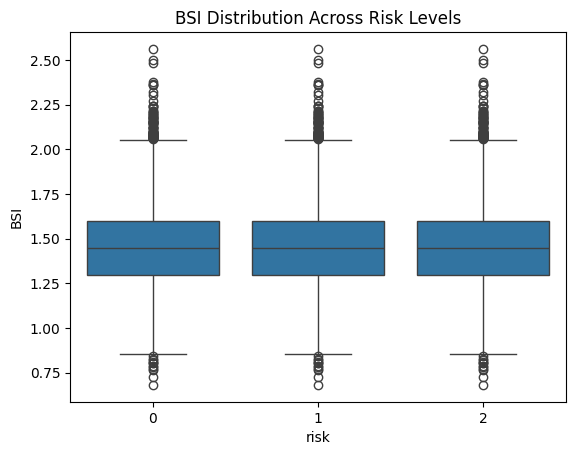

In [ ]:
import seaborn as sns

sns.boxplot(x="risk", y="BSI", data=data)
plt.title("BSI Distribution Across Risk Levels")
plt.show()

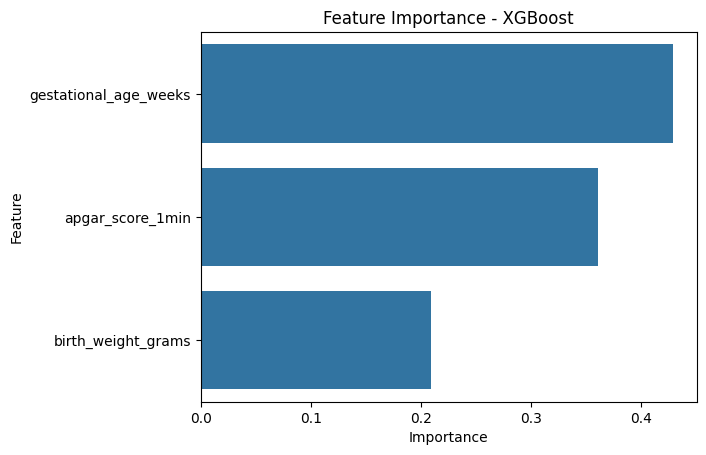

In [ ]:
import pandas as pd

importance = model_xgb.feature_importances_

feature_names = X_static.columns

feat_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feat_df = feat_df.sort_values(by="Importance", ascending=False)

sns.barplot(x="Importance", y="Feature", data=feat_df)
plt.title("Feature Importance - XGBoost")
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    prec = precision_score(
        y_test,
        y_pred,
        average="weighted"
    )

    rec = recall_score(
        y_test,
        y_pred,
        average="weighted"
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted"
    )

    results.append([
        name,
        acc,
        prec,
        rec,
        f1
    ])

baseline_results = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

print(baseline_results)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.468674   0.468403  0.468674  0.467845
1        Decision Tree  0.000000   0.000000  0.000000  0.000000
2        Random Forest  0.171928   0.158118  0.171928  0.164333


In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(23667, 9)
(6177, 9)
(23667,)
(6177,)


In [ ]:
print(y_train.value_counts())
print(y_test.value_counts())

risk
0    7889
1    7889
2    7889
Name: count, dtype: int64
risk
0    2059
1    2059
2    2059
Name: count, dtype: int64


In [ ]:
print(X_train.head())

   infant_id  heart_rate  spo2  radiation_level  emf_level  humidity  \
0          8  129.871689  95.6               70      16.53      48.9   
1          8  129.871689  95.6               70      16.53      48.9   
2          8  129.871689  95.6               70      16.53      48.9   
3          3  136.318291  95.8               91      14.94      53.2   
4          3  136.318291  95.8               91      14.94      53.2   

   gestational_age_weeks  birth_weight_grams  apgar_score_1min  
0                   35.0                2230                 6  
1                   39.2                2970                 7  
2                   35.4                2300                 5  
3                   39.6                3010                 9  
4                   37.1                2600                10  


In [ ]:
print(type(X_train))
print(type(y_train))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>


In [ ]:
print(X_train.columns)

Index(['infant_id', 'heart_rate', 'spo2', 'radiation_level', 'emf_level',
       'humidity', 'gestational_age_weeks', 'birth_weight_grams',
       'apgar_score_1min'],
      dtype='object')


In [ ]:
!pip install shap

In [ ]:
import shap

explainer = shap.Explainer(model_xgb)
shap_values = explainer(X_test)

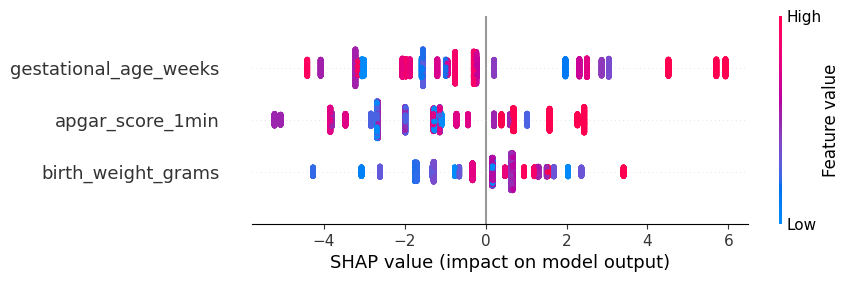

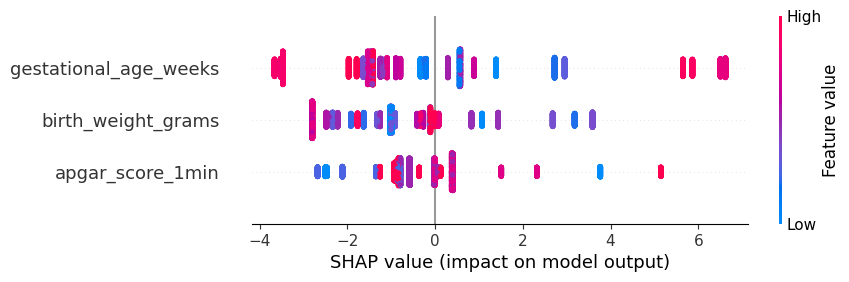

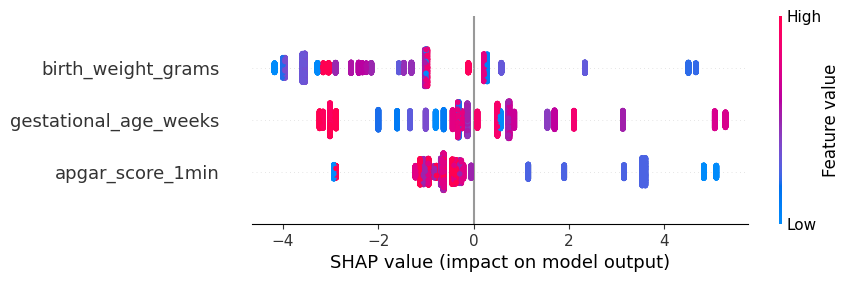

In [ ]:
# Low risk
shap.plots.beeswarm(shap_values[:, :, 0])

# Moderate risk
shap.plots.beeswarm(shap_values[:, :, 1])

# High risk (BEST ONE 🔥)
shap.plots.beeswarm(shap_values[:, :, 2])

In [ ]:
shap_value_single = shap_values[0, :, 2]   # class 2 = high risk

In [ ]:
base_value = explainer.expected_value[2]

In [ ]:
features = X_test.iloc[0]

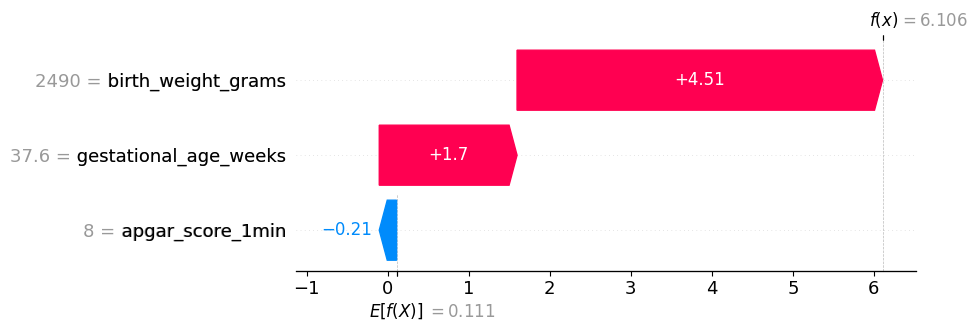

In [ ]:
shap.plots.waterfall(shap_values[0, :, 2])

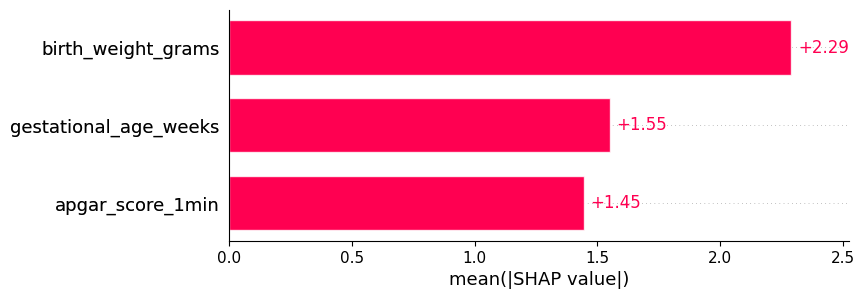

In [ ]:
shap.plots.bar(shap_values[:, :, 2])

In [ ]:
import joblib

joblib.dump(model_xgb, "xgb_model.pkl")
autoencoder.save("lstm_model.h5")

In [ ]:
import pandas as pd

# ----------------------------
# 1. LOAD DATASETS
# ----------------------------
low = pd.read_csv("neonatal_low_burden.csv")
moderate = pd.read_csv("neonatal_moderate_burden.csv")
high = pd.read_csv("neonatal_high_burden.csv")
sensor = pd.read_csv("realistic_nicu_sensor_data.csv")

# ----------------------------
# 2. ADD RISK LABELS
# ----------------------------
low["risk"] = 0
moderate["risk"] = 1
high["risk"] = 2

# ----------------------------
# 3. COMBINE CLINICAL DATA
# ----------------------------
clinical = pd.concat([low, moderate, high], ignore_index=True)

# ----------------------------
# 4. STANDARDIZE ID FORMAT
# ----------------------------

# Convert clinical id → int
clinical["id"] = clinical["id"].astype(int)

# Convert sensor id → int (remove 'infant_')
sensor["infant_id"] = sensor["infant_id"].str.replace("infant_", "").astype(int)

# Rename clinical id → match sensor
clinical = clinical.rename(columns={"id": "infant_id"})

# ----------------------------
# 5. FIX COLUMN NAMES (CLINICAL)
# ----------------------------
clinical = clinical.rename(columns={
    "gestational_age_weeks": "gestational_age_weeks",
    "birth_weight_g": "birth_weight_grams",
    "apgar_1min": "apgar_score_1min"
})

# ----------------------------
# 6. MERGE DATASETS
# ----------------------------
data = pd.merge(sensor, clinical, on="infant_id", how="left")

# ----------------------------
# ----------------------------
# AUTO-DETECT EMF COLUMN (SAFE)
# ----------------------------
emf_col = [c for c in data.columns if "emf" in c.lower()][0]

# ----------------------------
# SELECT RELEVANT COLUMNS
# ----------------------------
data = data[[
    "timestamp",
    "infant_id",
    "heart_rate_bpm_x",
    "spo2_pct",
    "radiation_counts_cpm",
    emf_col,   # ← FIXED
    "relative_humidity_pct",
    "gestational_age_weeks",
    "birth_weight_grams",
    "apgar_score_1min",
    "risk"
]]

# ----------------------------
# 8. RENAME FINAL COLUMNS
# ----------------------------
data = data.rename(columns={
    "heart_rate_bpm_x": "heart_rate",
    "spo2_pct": "spo2",
    "radiation_counts_cpm": "radiation_level",
    "emf_peak_μt": "emf_level",
    "relative_humidity_pct": "humidity"
})

# ----------------------------
# 9. CLEAN DATA
# ----------------------------
data = data.drop_duplicates()

# ----------------------------
# 10. FINAL CHECK
# ----------------------------
print("Final Dataset Preview:")
print(data.head())

print("\nColumns:")
print(data.columns)

print("\nShape:")
print(data.shape)

# ----------------------------
# 11. SAVE DATASET
# ----------------------------
data.to_csv("nicu_combined_dataset.csv", index=False)

print("\n✅ Dataset successfully merged and saved as 'nicu_combined_dataset.csv'")

Final Dataset Preview:
             timestamp  infant_id  heart_rate  spo2  radiation_level  \
0  2025-12-29T10:00:00          8  129.871689  95.6               70   
1  2025-12-29T10:00:00          8  129.871689  95.6               70   
2  2025-12-29T10:00:00          8  129.871689  95.6               70   
3  2025-12-29T10:00:01          3  136.318291  95.8               91   
4  2025-12-29T10:00:01          3  136.318291  95.8               91   

   emf_peak_μT  humidity  gestational_age_weeks  birth_weight_grams  \
0        16.53      48.9                   35.0                2230   
1        16.53      48.9                   39.2                2970   
2        16.53      48.9                   35.4                2300   
3        14.94      53.2                   39.6                3010   
4        14.94      53.2                   37.1                2600   

   apgar_score_1min  risk  
0                 6     0  
1                 7     1  
2                 5     2  
3    

In [ ]:
import pandas as pd

data = pd.read_csv("nicu_combined_dataset.csv")

for col in data.columns:
    print(col)

timestamp
infant_id
heart_rate
spo2
radiation_level
emf_peak_μT
humidity
gestational_age_weeks
birth_weight_grams
apgar_score_1min
risk


In [ ]:
data = data.rename(columns={
    "emf_peak_μT": "emf_level"
})

In [ ]:
print(data.columns.tolist())

['timestamp', 'infant_id', 'heart_rate', 'spo2', 'radiation_level', 'emf_level', 'humidity', 'gestational_age_weeks', 'birth_weight_grams', 'apgar_score_1min', 'risk']


In [ ]:
data = data.rename(columns={
    "emf_peak_μT": "emf_level"   # ← capital T
})

In [ ]:
print("emf_level" in data.columns)

True


In [ ]:
numeric_cols = [
    "heart_rate", "spo2", "radiation_level", "emf_level",
    "humidity", "gestational_age_weeks",
    "birth_weight_grams", "apgar_score_1min"
]

for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

In [ ]:
import pandas as pd
import numpy as np

# ----------------------------
# LOAD DATA (ONLY ONCE)
# ----------------------------
data = pd.read_csv("nicu_combined_dataset.csv")

# ----------------------------
# FIX EMF COLUMN (AUTO-DETECT SAFE)
# ----------------------------
emf_cols = [c for c in data.columns if "emf" in c.lower()]
if len(emf_cols) == 0:
    raise ValueError("❌ No EMF column found in dataset")

emf_col = emf_cols[0]   # pick first match
data = data.rename(columns={emf_col: "emf_level"})

# ----------------------------
# HANDLE MISSING VALUES
# ----------------------------
data["gestational_age_weeks"] = data["gestational_age_weeks"].fillna(
    data["gestational_age_weeks"].median()
)

data["birth_weight_grams"] = data["birth_weight_grams"].fillna(
    data["birth_weight_grams"].median()
)

data["apgar_score_1min"] = data["apgar_score_1min"].fillna(
    data["apgar_score_1min"].median()
)

data["risk"] = data["risk"].fillna(
    data["risk"].mode()[0]
)

# ----------------------------
# DATA TYPE CONVERSION
# ----------------------------
data["timestamp"] = pd.to_datetime(data["timestamp"])

numeric_cols = [
    "heart_rate", "spo2", "radiation_level", "emf_level",
    "humidity", "gestational_age_weeks",
    "birth_weight_grams", "apgar_score_1min"
]

for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# ----------------------------
# REMOVE OUTLIERS
# ----------------------------
data = data[(data["spo2"] <= 100) & (data["spo2"] >= 70)]
data = data[(data["heart_rate"] >= 80) & (data["heart_rate"] <= 200)]

# ----------------------------
# FEATURE ENGINEERING → BSI
# ----------------------------
data["BSI"] = (
    abs(data["heart_rate"] - 140) +
    (100 - data["spo2"]) +
    (data["radiation_level"] * 0.01)
)

# ----------------------------
# RISK LABEL (FOR DASHBOARD)
# ----------------------------
data["risk_label"] = data["risk"].map({
    0: "Low",
    1: "Moderate",
    2: "High"
})

# ----------------------------
# SORT BY TIME
# ----------------------------
data = data.sort_values(by="timestamp")

# ----------------------------
# FINAL CHECK
# ----------------------------
print("✅ Missing values:\n", data.isnull().sum())
print("\n✅ Shape:", data.shape)
print("\n✅ Columns:", data.columns.tolist())

# ----------------------------
# SAVE FINAL DATASET
# ----------------------------
data.to_csv("nicu_bi_ready_dataset.csv", index=False)

print("\n🔥 BI-ready dataset saved as 'nicu_bi_ready_dataset.csv'")

✅ Missing values:
 timestamp                0
infant_id                0
heart_rate               0
spo2                     0
radiation_level          0
emf_level                0
humidity                 0
gestational_age_weeks    0
birth_weight_grams       0
apgar_score_1min         0
risk                     0
BSI                      0
risk_label               0
dtype: int64

✅ Shape: (29844, 13)

✅ Columns: ['timestamp', 'infant_id', 'heart_rate', 'spo2', 'radiation_level', 'emf_level', 'humidity', 'gestational_age_weeks', 'birth_weight_grams', 'apgar_score_1min', 'risk', 'BSI', 'risk_label']

🔥 BI-ready dataset saved as 'nicu_bi_ready_dataset.csv'


In [ ]:
print(X_test.columns)

Index(['infant_id', 'heart_rate', 'spo2', 'radiation_level', 'emf_level',
       'humidity', 'gestational_age_weeks', 'birth_weight_grams',
       'apgar_score_1min'],
      dtype='object')


In [ ]:
print(X_static.columns)

Index(['gestational_age_weeks', 'birth_weight_grams', 'apgar_score_1min'], dtype='object')


In [ ]:
from sklearn.model_selection import train_test_split

X_train_roc, X_test_roc, y_train_roc, y_test_roc = train_test_split(
    X_static,
    y_static,
    test_size=0.20,
    random_state=42,
    stratify=y_static
)

In [ ]:
from xgboost import XGBClassifier

model_roc = XGBClassifier(
    random_state=42,
    eval_metric="mlogloss"
)

model_roc.fit(X_train_roc, y_train_roc)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
print(X_static.columns)
print(y_static.head())

Index(['gestational_age_weeks', 'birth_weight_grams', 'apgar_score_1min'], dtype='object')
0    0
1    1
2    2
3    0
4    1
Name: risk, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train_roc, X_test_roc, y_train_roc, y_test_roc = train_test_split(
    X_static,
    y_static,
    test_size=0.2,
    random_state=42,
    stratify=y_static
)

In [ ]:
from xgboost import XGBClassifier

model_roc = XGBClassifier(
    random_state=42,
    eval_metric="mlogloss"
)

model_roc.fit(X_train_roc, y_train_roc)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
print(model_roc.feature_names_in_)
print(X_test_roc.columns)

['gestational_age_weeks' 'birth_weight_grams' 'apgar_score_1min']
Index(['gestational_age_weeks', 'birth_weight_grams', 'apgar_score_1min'], dtype='object')


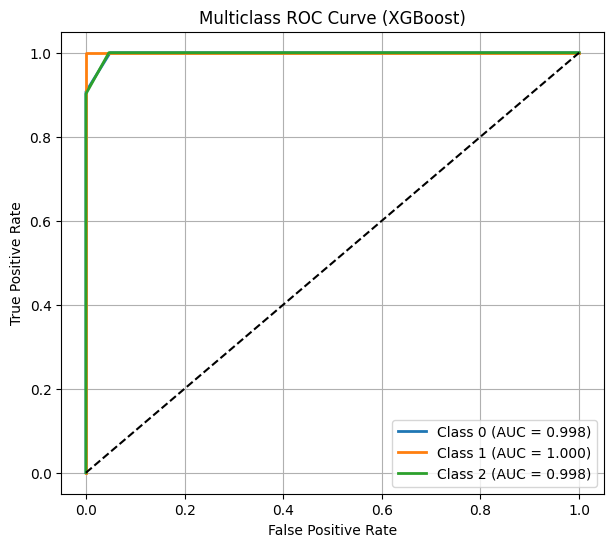

<Figure size 640x480 with 0 Axes>

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_score = model_roc.predict_proba(X_test_roc)

y_test_bin = label_binarize(y_test_roc, classes=[0, 1, 2])

plt.figure(figsize=(7,6))

for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"Class {i} (AUC = {roc_auc:.3f})")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve (XGBoost)")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()
plt.savefig("Fig13_ROC_XGBoost.png", dpi=600, bbox_inches="tight")

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Predict probabilities
y_score = model_xgb.predict_proba(X_test)

# Convert labels to binary
y_test_bin = label_binarize(y_test, classes=[0,1,2])

plt.figure(figsize=(7,6))

colors = ["blue","orange","green"]

for i, color in zip(range(3), colors):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        color=color,
        linewidth=2,
        label=f"Class {i} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0,1],
    [0,1],
    "k--",
    linewidth=1
)

plt.xlim([0,1])
plt.ylim([0,1.05])

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title("Multiclass ROC Curve for XGBoost", fontsize=14)

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "roc_curve_xgboost.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

ValueError: feature_names mismatch: ['gestational_age_weeks', 'birth_weight_grams', 'apgar_score_1min'] ['infant_id', 'heart_rate', 'spo2', 'radiation_level', 'emf_level', 'humidity', 'gestational_age_weeks', 'birth_weight_grams', 'apgar_score_1min']
training data did not have the following fields: radiation_level, emf_level, infant_id, humidity, heart_rate, spo2

In [ ]:
# Features (IMPORTANT: remove leakage columns)
X = data.drop(columns=["risk"])   # target removed

# Target
y = data["risk"]

In [ ]:
X = data.drop(columns=["risk"])
y = data["risk"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
X = data.drop(columns=[
    "risk",         # target
    "risk_label",   # text
    "timestamp",    # datetime
    "infant_id"     # ID (not useful)
])

y = data["risk"]

In [ ]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# Remove invalid columns
X = data.drop(columns=["risk", "risk_label", "timestamp", "infant_id"])
y = data["risk"]

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train
model = XGBClassifier()
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

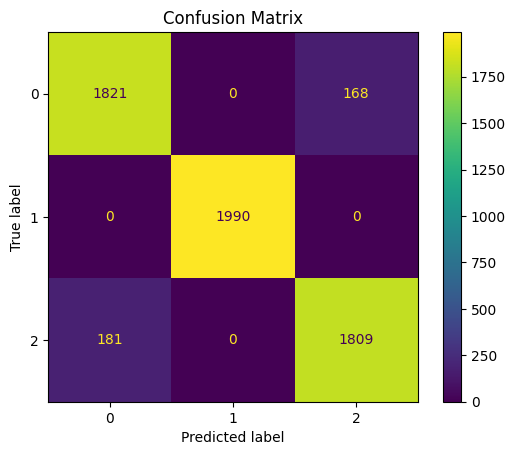

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.92      0.91      1989
           1       1.00      1.00      1.00      1990
           2       0.92      0.91      0.91      1990

    accuracy                           0.94      5969
   macro avg       0.94      0.94      0.94      5969
weighted avg       0.94      0.94      0.94      5969



In [ ]:
X_train = X_train + np.random.normal(0, 0.02, X_train.shape)

In [ ]:
X = X.drop(columns=["BSI"])

In [ ]:
print(y_test.value_counts())

risk
2    1990
1    1990
0    1989
Name: count, dtype: int64


In [ ]:
corr = data.select_dtypes(include=["number"]).corr()
print(corr["risk"].sort_values(ascending=False))

risk                     1.000000e+00
BSI                      8.966753e-17
humidity                 4.530305e-17
heart_rate               1.885952e-17
infant_id               -4.236534e-18
radiation_level         -1.077226e-17
spo2                    -2.764254e-17
emf_level               -5.139987e-17
birth_weight_grams      -2.636511e-01
gestational_age_weeks   -3.238353e-01
apgar_score_1min        -3.984432e-01
Name: risk, dtype: float64


In [ ]:
# Step 1: Remove BSI
data = data.drop(columns=["BSI"])

# Step 2: Prepare features
X = data.drop(columns=["risk", "risk_label", "timestamp", "infant_id"])
y = data["risk"]

# Step 3: Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Add noise
X_train = X_train + np.random.normal(0, 0.02, X_train.shape)

# Step 5: Train again
model = XGBClassifier()
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

X = data.drop(columns=["risk", "risk_label", "timestamp"])
y = data["risk"]
groups = data["infant_id"]

gss = GroupShuffleSplit(test_size=0.2, random_state=42)

train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

In [ ]:
model = XGBClassifier()
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
X = data.drop(columns=["risk", "risk_label", "timestamp", "infant_id"])
y = data["risk"]
groups = data["infant_id"]

In [ ]:
model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    eval_metric="mlogloss"
)

model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

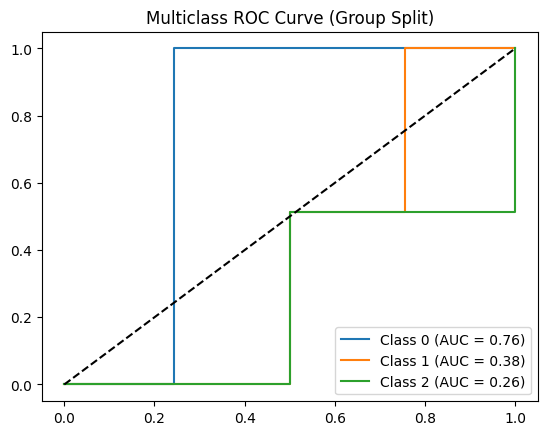

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_test_bin = label_binarize(y_test, classes=[0,1,2])
y_pred_prob = model.predict_proba(X_test)

plt.figure()

for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Class {i} (AUC = {roc_auc:.2f})")

plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title("Multiclass ROC Curve (Group Split)")
plt.show()

In [ ]:
print(len(set(data.iloc[train_idx]["infant_id"]) & set(data.iloc[test_idx]["infant_id"])))

0


In [ ]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.17079488424801684


In [ ]:
import time
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss
)

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=5000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="mlogloss"
    )
}

In [ ]:
comparison_results = []

for name, model in models.items():

    start = time.time()

    model.fit(X_train_cmp, y_train_cmp)

    training_time = time.time() - start

    y_pred = model.predict(X_test_cmp)

    y_prob = model.predict_proba(X_test_cmp)

    comparison_results.append({

        "Model": name,

        "Accuracy":
            accuracy_score(y_test_cmp, y_pred),

        "Precision":
            precision_score(
                y_test_cmp,
                y_pred,
                average="weighted"
            ),

        "Recall":
            recall_score(
                y_test_cmp,
                y_pred,
                average="weighted"
            ),

        "F1-Score":
            f1_score(
                y_test_cmp,
                y_pred,
                average="weighted"
            ),

        "ROC-AUC":
            roc_auc_score(
                y_test_cmp,
                y_prob,
                multi_class="ovr"
            ),

        "Log Loss":
            log_loss(
                y_test_cmp,
                y_prob
            ),

        "Training Time (s)":
            training_time
    })

In [ ]:
comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.round(4)

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Log Loss,Training Time (s)
0,Logistic Regression,0.5250,0.5219,0.5250,0.5178,0.6510,0.9995,4.0313
1,Decision Tree,0.9673,0.9702,0.9673,0.9673,0.9985,0.0441,0.0129
2,Random Forest,0.9673,0.9702,0.9673,0.9673,0.9985,0.0441,0.4873
3,XGBoost,0.9673,0.9702,0.9673,0.9673,0.9985,0.0443,0.4907
